Task 1: Temperature

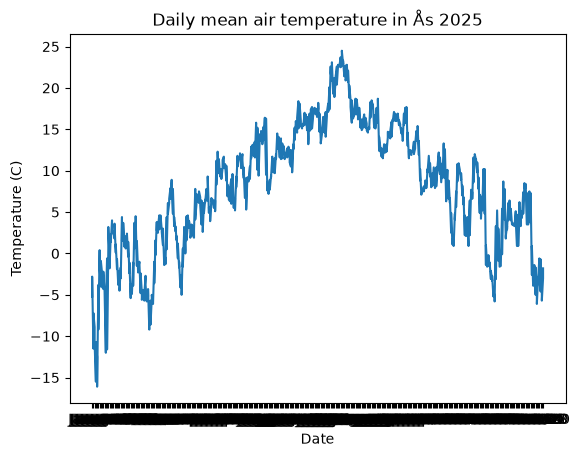

        ---Summary---
mean:            7.90
median:          8.35
min:           -16.10
max:            24.50


In [ ]:
import datetime as dt
import matplotlib.pyplot as plt
import pandas as pd
import requests


endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {'sources': 'SN17850',
              'elements': 'mean(air_temperature P1D)',
              'referencetime': '2025-01-01/2025-12-31',
             }

client_id = open('/Users/norahattrem/Desktop/Programmering/Visual Studio Code/INF201/frost_credentials.txt').read().strip()

task1_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert task1_response.status_code == 200

task1_json = task1_response.json()

task1_data = task1_json['data']

# This will return a Dataframe with all of the observations in a table format
task1_list = []
task1_df = pd.DataFrame()
for i in range(len(task1_data)):
    row = pd.DataFrame(task1_data[i]['observations'])
    row['referenceTime'] = dt.datetime.strftime(dt.datetime.fromisoformat(task1_data[i]['referenceTime']), '%b, %d')
    row['sourceId'] = task1_data[i]['sourceId']
    task1_list.append(row)

task1_df = pd.concat(task1_list)
task1_df = task1_df.reset_index()

task2_summary = {'---Summary---': [f'{task1_df["value"].mean():.2f}', f'{task1_df["value"].median():.2f}', f'{task1_df["value"].min():.2f}', f'{task1_df["value"].max():.2f}']}
task2_summary_df = pd.DataFrame(task2_summary, index=['mean:', 'median:', 'min:', 'max:'])

plt.plot(task1_df['referenceTime'], task1_df['value'], label='2025')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.title('Daily mean air temperature in Ås 2025')
plt.show()

print(task2_summary_df)

# Fix dates

Resources: 
https://frost.met.no/python_example.html

https://www.w3schools.com/python/pandas/pandas_dataframes.asp

Task 2: Precipitation

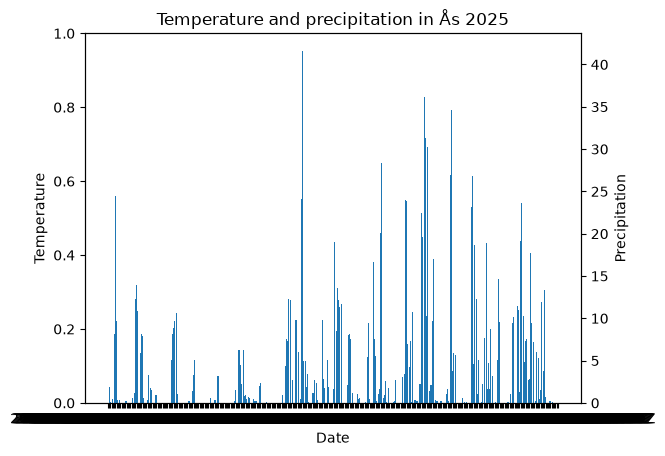

In [3]:
parameters = {'sources': 'SN17850',
              'elements': 'sum(precipitation_amount P1D)',
              'referencetime': '2025-01-01/2025-12-31',
            }

task2_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert task2_response.status_code == 200

task2_json = task2_response.json()

task2_data = task2_json['data']

task2_list = []
df2 = pd.DataFrame()
for i in range(len(task2_data)):
    row = pd.DataFrame(task2_data[i]['observations'])
    row['referenceTime'] = task2_data[i]['referenceTime']
    row['sourceId'] = task2_data[i]['sourceId']
    task2_list.append(row)

task2_df = pd.concat(task2_list)
task2_df = task2_df.reset_index()

fig, ax1 = plt.subplots()

ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature')
ax2 = ax1.twinx()
ax2.bar(task2_df['referenceTime'], task2_df['value'], label='Precipitation')
ax2.set_ylabel('Precipitation')

plt.title('Temperature and precipitation in Ås 2025')
plt.show()

Resources:
https://pythonguides.com/matplotlib-two-y-axes-bar-plot/

Task 3: Historical temperature data

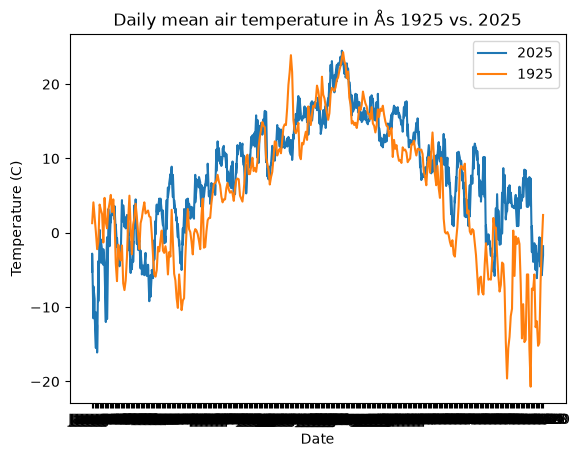

     ---Summary---     
           1925    2025
mean:      5.31    7.90
median:    5.30    8.35
min:     -20.70  -16.10
max:      24.30   24.50


In [ ]:
parameters = {'sources': 'SN17850',
              'elements': 'mean(air_temperature P1D)',
              'referencetime': '1925-01-01/1925-12-31',
             }

task3_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert task3_response.status_code == 200

task3_json = task3_response.json()
task3_data = task3_json['data']

task3_list = []
task3_df = pd.DataFrame()
for i in range(len(task3_data)):
    row = pd.DataFrame(task3_data[i]['observations'])
    row['referenceTime'] = dt.datetime.strftime(dt.datetime.fromisoformat(task3_data[i]['referenceTime']),'%b, %d')
    row['sourceId'] = task3_data[i]['sourceId']
    task3_list.append(row)

task3_df = pd.concat(task3_list)
task3_df = task3_df.reset_index()

task3_summary = {'1925': [f'{task3_df["value"].mean():.2f}', f'{task3_df["value"].median():.2f}', f'{task3_df["value"].min():.2f}', f'{task3_df["value"].max():.2f}'],
     '2025': [f'{task1_df["value"].mean():.2f}', f'{task1_df["value"].median():.2f}', f'{task1_df["value"].min():.2f}', f'{task1_df["value"].max():.2f}']}
task3_summary_df = pd.DataFrame(task3_summary, index=['mean:', 'median:', 'min:', 'max:'])

plt.plot(task1_df['referenceTime'], task1_df['value'], label='2025')
plt.plot(task3_df['referenceTime'], task3_df['value'], label='1925')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.title('Daily mean air temperature in Ås 1925 vs. 2025')
plt.legend()
plt.show()

print(f'     ---Summary---     \n{task3_summary_df}')


Task 4: Heatwaves

In [ ]:
import datetime as dt
import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml


endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {'sources': 'SN17850',
              'elements': 'max(air_temperature P1D)',
              'referencetime': '2025-01-01/2025-12-31',
             }

client_id = ("9ac239fe-b894-4f43-ade1-f6e059182567")

task4_response = requests.get(endpoint, parameters, auth=(client_id, ""))
assert task4_response.status_code == 200

task4_json = task4_response.json()
task4_data = task4_json['data']

task4_list = []
task4_df = pd.DataFrame()
for i in range(len(task4_data)):
    row = pd.DataFrame(task4_data[i]['observations'])
    row['referenceTime'] = task4_data[i]['referenceTime']
    row['sourceId'] = task4_data[i]['sourceId']
    task4_list.append(row)

task4_df = pd.concat(task4_list)
task4_df = task4_df.reset_index()


def task_4(task4_df):
    temperature = task4_df["value"]
    year = task4_df["referenceTime"].iloc[0][:4]
    station_id = task4_df["sourceId"].iloc[0][:7]

    days = 0
    heatwaves = 0
    first_date = 0
    last_date = 0

    for i, temp in enumerate(temperature):
        if temp >= 27:
            days += 1

            if days == 1:
                start = task4_df["referenceTime"].iloc[i][:10]

            if days == 5:
                heatwaves += 1
                first_date = start

        else:
            if days >= 5:
                end = task4_df["referenceTime"].iloc[i-1][:10]
                last_date = end

            days = 0


        dates = [first_date, last_date]
        
        summary = {
        "dates": dates, 
        "station_id": station_id,
        "year": year,
    }

    with open("heatwaves.yml", "w", encoding="utf-8") as file:
        yaml.dump(summary, file, sort_keys=False)

    return summary

result = task_4(task4_df)
print(result) 

{'dates': ['2025-07-16', '2025-07-20'], 'station_id': 'SN17850', 'year': '2025'}


Task 5: Moving average temperature